In [276]:
# stage 1 packages

import random
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sb

import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import time

# stage 2 packages

from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.nn.utils import clip_grad_norm_

In [278]:
# define constants

BATCH_SIZE = 64
DATA_PATH = "../data/en-US.jsonl"
SEED = 0
EMBEDDING_DIM = 100
HIDDEN_DIM = 128
LEARNING_RATE_SGD = 0.1
NUM_EPOCHS_SGD = 80
LEARNING_RATE_ADAM = 0.001
NUM_EPOCHS_ADAM = 40
NUM_EPOCHS_EXP3 = 100
DROPOUT = 0.3
MAX_GRAD_NORM = 1.0

In [197]:
# set random seeds for reproducibility

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Exploratory Data Analysis

In [198]:
# load amazon massive dataset

massive_df = pd.read_json(DATA_PATH, lines=True)
print(massive_df.head())

   id locale partition scenario             intent  \
0   0  en-US      test    alarm          alarm_set   
1   1  en-US     train    alarm          alarm_set   
2   2  en-US     train    alarm          alarm_set   
3   3  en-US      test    audio  audio_volume_mute   
4   4  en-US     train    audio  audio_volume_mute   

                                   utt  \
0      wake me up at five am this week   
1      wake me up at nine am on friday   
2  set an alarm for two hours from now   
3                                quiet   
4                           olly quiet   

                                           annot_utt  worker_id  
0  wake me up at [time : five am] [date : this week]          1  
1  wake me up at [time : nine am] on [date : friday]          1  
2       set an alarm for [time : two hours from now]          1  
3                                              quiet          1  
4                                         olly quiet          1  


In [199]:
# split by partition (train, test, validation)
# train_df is used for training, val_df is used for hyperparameter tuning, test_df is used for evaluation
train_df = massive_df[massive_df['partition'] == 'train'].reset_index(drop=True)
val_df = massive_df[massive_df['partition'] == 'dev'].reset_index(drop=True)
test_df = massive_df[massive_df['partition'] == 'test'].reset_index(drop=True)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}\n")

# check for data mismatch
if (len(train_df), len(val_df), len(test_df)) != (11514, 2033, 2974):
    print("\nData mismatch.")
    print(f"  • Expected: Train=11514, Val=2033, Test=2974")
    print(f"  • Received: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")
    
    assert False, "Partition row counts do not match the expected dataset schema."
else:
    print("Success. All partition sizes match the benchmark exactly.")
    pass 

Train: 11514 | Val: 2033 | Test: 2974

Success. All partition sizes match the benchmark exactly.


In [200]:
# view examples of utt, intent, annot_utt

print(train_df[['utt', 'intent', 'annot_utt']].head(10))

                                            utt               intent  \
0               wake me up at nine am on friday            alarm_set   
1           set an alarm for two hours from now            alarm_set   
2                                    olly quiet    audio_volume_mute   
3                                          stop    audio_volume_mute   
4                    olly pause for ten seconds    audio_volume_mute   
5                         pause for ten seconds    audio_volume_mute   
6          make the lighting bit more warm here  iot_hue_lightchange   
7  please set the lighting suitable for reading  iot_hue_lightchange   
8                                 time to sleep     iot_hue_lightoff   
9                            time to sleep olly     iot_hue_lightoff   

                                           annot_utt  
0  wake me up at [time : nine am] on [date : friday]  
1       set an alarm for [time : two hours from now]  
2                                         

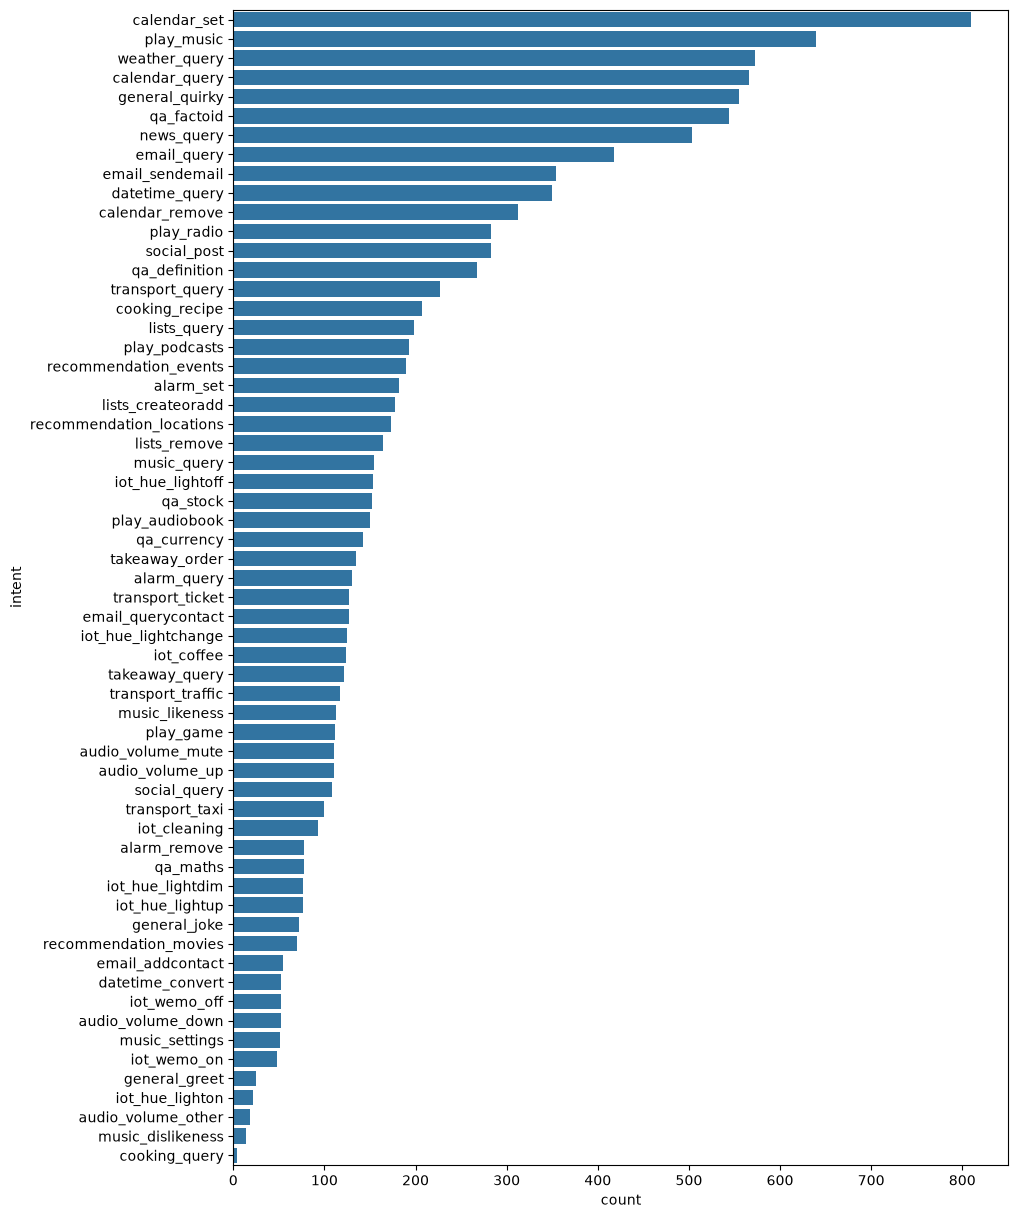

In [201]:
# check intent distribution

plt.figure(figsize=(10, 15)) 
sb.countplot(data=train_df, y='intent', order=train_df['intent'].value_counts().index)
plt.show()

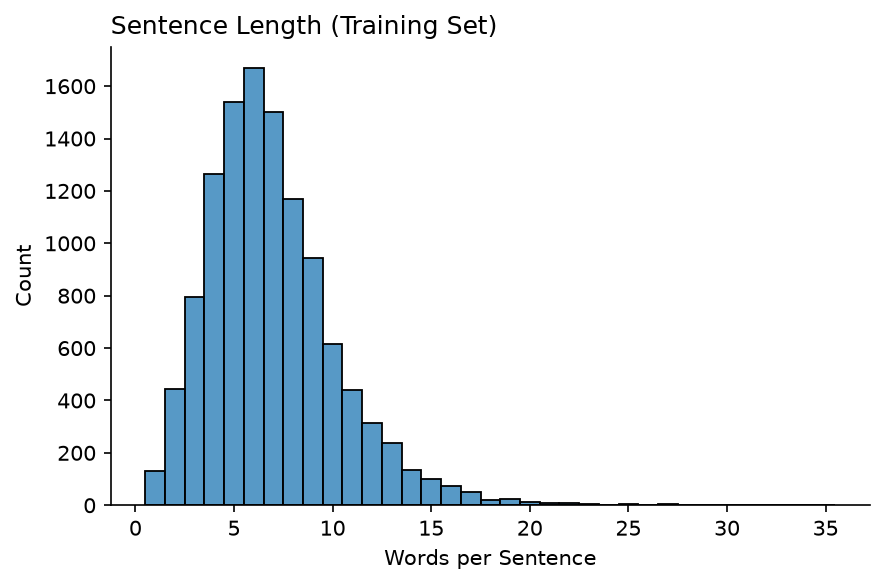

In [202]:
# get token count per entry
train_df['n_tokens'] = train_df['utt'].str.split().str.len()

# sentence length distribution
fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
sb.histplot(data=train_df, x="n_tokens", ax=ax, discrete=True)
ax.set_title("Sentence Length (Training Set)", loc="left")
ax.set_xlabel("Words per Sentence")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

In [203]:
# get all words from train place them in an array
train_words = train_df['utt'].str.split().explode()

# get unique words 
train_vocab_size = train_words.nunique()

print(f"Vocabulary Size: {train_vocab_size}")

Vocabulary Size: 5302


In [204]:
# get words in dev and test set that does not appear in train

# get all words from train place them in an array
train_vocab = set(train_df['utt'].str.split().explode())

# get all words from dev place them in an array
val_vocab = set(val_df['utt'].str.split().explode())

# get all words from test place them in an array
test_vocab = set(test_df['utt'].str.split().explode())

val_unk_words = val_vocab - train_vocab
test_unk_words = test_vocab - train_vocab

print(f"Number of unknown words in validation set: {len(val_unk_words)}")
print(f"Sample of unknown words in validation set: {list(val_unk_words)[:10]}\n")
print(f"Number of unknown words in test set: {len(test_unk_words)}")
print(f"Sample of unknown words in test set: {list(test_unk_words)[:10]}")

Number of unknown words in validation set: 439
Sample of unknown words in validation set: ['though', 'resistor', 'framework', 'superb', 'aww', 'groomer', 'clearer', 'recorder', "afi's", 'approval']

Number of unknown words in test set: 653
Sample of unknown words in test set: ['jerk', 'stomachs', 'margaret', 'notebook', 'broil', 'mirchi', 'clans', 'eagles', 'considered', 'silently']


In [205]:
# count entries with no slot

no_slots_mask = ~train_df['annot_utt'].str.contains('\[', na=False)
no_slots_count = no_slots_mask.sum()
no_slots_percentage = (no_slots_count / len(train_df)) * 100

print(f"Sentences with no slots: {no_slots_count}")
print(f"Percentage of total data: {no_slots_percentage:.2f}%")

Sentences with no slots: 3755
Percentage of total data: 32.61%


<>:3: SyntaxWarning: invalid escape sequence '\['
<>:3: SyntaxWarning: invalid escape sequence '\['
/var/folders/w8/d9x92py92j792gw_1kyfc8sh0000gn/T/ipykernel_71944/1044832266.py:3: SyntaxWarning: invalid escape sequence '\['
  no_slots_mask = ~train_df['annot_utt'].str.contains('\[', na=False)


In [206]:
# count slot entries

slot_series = train_df['annot_utt'].str.findall(r'\[([a-zA-Z0-9_\-]+)\s*:')
slot_counts = slot_series.explode().value_counts()

print("----- Slot Type Counts -----")
print(slot_counts)

----- Slot Type Counts -----
annot_utt
date                    1816
place_name              1086
event_name               998
person                   864
time                     797
media_type               477
business_name            383
weather_descriptor       320
transport_type           318
food_type                295
relation                 251
timeofday                239
artist_name              232
device_type              226
definition_word          225
currency_name            217
house_place              198
list_name                191
business_type            189
news_topic               183
music_genre              181
player_setting           160
radio_name               131
song_name                128
order_type               107
color_type               100
game_name                 87
general_frequency         84
personal_info             75
audiobook_name            73
podcast_descriptor        68
meal_type                 63
playlist_name             62
time

# Pre-Processing

In [207]:
# build vocabulary. no tf-idf or bag of words as it loses word order

train_vocab_list = sorted(list(train_vocab))

word_to_idx = {"<PAD>": 0, "<UNK>": 1}
for idx, word in enumerate(train_vocab_list, start=2):
    word_to_idx[word] = idx

print(f"Vocabulary size: {len(word_to_idx)}\n")

if len(word_to_idx) != len(train_vocab_list) + 2:
    assert False, "Vocabulary size is not expected."
else:
    print("Success. Vocabulary size is as expected.")
    pass 

print(word_to_idx)

Vocabulary size: 5304

Success. Vocabulary size is as expected.
{'<PAD>': 0, '<UNK>': 1, '&': 2, '<empty>': 3, 'a': 4, 'a.': 5, 'aa': 6, 'aapa': 7, 'aaron': 8, 'abdul': 9, 'abita': 10, 'able': 11, 'abolish': 12, 'about': 13, 'above': 14, 'abraham': 15, 'abs': 16, 'absolute': 17, 'acceleration': 18, 'accept': 19, 'access': 20, 'accident': 21, 'accidents': 22, 'accommodating': 23, 'according': 24, 'accordingly': 25, 'account': 26, 'accounting': 27, 'accumulation': 28, 'acela': 29, 'acer': 30, 'achievements': 31, 'acme': 32, 'acoustic': 33, 'acoustical': 34, 'acquire': 35, 'across': 36, 'act': 37, 'action': 38, 'activate': 39, 'activated': 40, 'activates': 41, 'active': 42, 'activities': 43, 'activity': 44, 'actor': 45, 'actors': 46, 'actress': 47, 'actual': 48, 'actually': 49, 'adam': 50, 'adams': 51, 'adapt': 52, 'add': 53, 'added': 54, 'addition': 55, 'additional': 56, 'address': 57, 'addresses': 58, 'adele': 59, 'adjust': 60, 'adjustments': 61, 'administrator': 62, 'adopters': 63, 'ad

In [208]:
# encode vocabulary into integer ids

def vocab_encoding(text, vocab_dict):
    encoding_list = []
    tokens = str(text).lower().split()
    
    for token in tokens:
        if token in vocab_dict:
            integer_id = vocab_dict[token]
        else:
            integer_id = vocab_dict["<UNK>"]

        encoding_list.append(integer_id)
    return encoding_list

train_df['encoded_utt'] = train_df['utt'].apply(lambda x: vocab_encoding(x, word_to_idx))
val_df['encoded_utt'] = val_df['utt'].apply(lambda x: vocab_encoding(x, word_to_idx))
test_df['encoded_utt'] = test_df['utt'].apply(lambda x: vocab_encoding(x, word_to_idx))

print(train_df.head(10))

   id locale partition scenario               intent  \
0   1  en-US     train    alarm            alarm_set   
1   2  en-US     train    alarm            alarm_set   
2   4  en-US     train    audio    audio_volume_mute   
3   5  en-US     train    audio    audio_volume_mute   
4   6  en-US     train    audio    audio_volume_mute   
5   7  en-US     train    audio    audio_volume_mute   
6   9  en-US     train      iot  iot_hue_lightchange   
7  10  en-US     train      iot  iot_hue_lightchange   
8  12  en-US     train      iot     iot_hue_lightoff   
9  13  en-US     train      iot     iot_hue_lightoff   

                                            utt  \
0               wake me up at nine am on friday   
1           set an alarm for two hours from now   
2                                    olly quiet   
3                                          stop   
4                    olly pause for ten seconds   
5                         pause for ten seconds   
6          make the lighti

In [209]:
# perform bio tagging to identify slots

def bio_tagging(annot_utt):
    tokens = []
    bio_tags = []
    
    current_label = "O"
    is_inside_entity = False
    is_first_word = False
    
    for piece in annot_utt.split():
        if piece.startswith("["):
            current_label = piece[1:] # remove open bracket
            is_inside_entity = True
            is_first_word = True
            continue
            
        if piece == ":":
            continue
            
        has_closing = False
        if piece.endswith("]"):
            piece = piece[:-1] # remove close bracket
            has_closing = True
            
        if is_inside_entity:
            if is_first_word:
                tag = f"B-{current_label}" 
            else: 
                tag = f"I-{current_label}"
            is_first_word = False
        else:
            tag = "O"
            
        tokens.append(piece)
        bio_tags.append(tag)
        
        if has_closing:
            is_inside_entity = False
            current_label = "O"
            
    return pd.Series({"tokens": tokens, "bio_tags": bio_tags})

train_df[["tokens", "bio_tags"]] = train_df["annot_utt"].apply(lambda x: bio_tagging(x))
val_df[["tokens", "bio_tags"]] = val_df["annot_utt"].apply(lambda x: bio_tagging(x))
test_df[["tokens", "bio_tags"]] = test_df["annot_utt"].apply(lambda x: bio_tagging(x))

In [210]:
print(train_df[["annot_utt", "tokens", "bio_tags"]].head())

                                           annot_utt  \
0  wake me up at [time : nine am] on [date : friday]   
1       set an alarm for [time : two hours from now]   
2                                         olly quiet   
3                                               stop   
4                olly pause for [time : ten seconds]   

                                         tokens  \
0      [wake, me, up, at, nine, am, on, friday]   
1  [set, an, alarm, for, two, hours, from, now]   
2                                 [olly, quiet]   
3                                        [stop]   
4              [olly, pause, for, ten, seconds]   

                                       bio_tags  
0       [O, O, O, O, B-time, I-time, O, B-date]  
1  [O, O, O, O, B-time, I-time, I-time, I-time]  
2                                        [O, O]  
3                                           [O]  
4                     [O, O, O, B-time, I-time]  


In [211]:
# validate token and tag lengths

dataframes = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

for name, df in dataframes.items():
    token_length = df["encoded_utt"].apply(len)
    tag_length = df["bio_tags"].apply(len)

    mismatched_rows = df[token_length != tag_length]

    if not mismatched_rows.empty:
        print(mismatched_rows)
        assert False, f"Mismatch found in {name} split."
    else:
        print(f"{name} split passed. Token lengths equal tag lengths.")

Train split passed. Token lengths equal tag lengths.
Validation split passed. Token lengths equal tag lengths.
Test split passed. Token lengths equal tag lengths.


In [212]:
# build bio tag vocabulary

biotag_vocab_list = sorted(train_df['bio_tags'].explode().unique())

biotag_vocab_list_clean = biotag_vocab_list.copy()
biotag_vocab_list_clean.remove('O')

tag_to_idx = {"O": 0}
for idx, word in enumerate(biotag_vocab_list_clean, start=1):
    tag_to_idx[word] = idx

print(f"Vocabulary size: {len(tag_to_idx)}\n")

print(tag_to_idx)

Vocabulary size: 107

{'O': 0, 'B-alarm_type': 1, 'B-app_name': 2, 'B-artist_name': 3, 'B-audiobook_author': 4, 'B-audiobook_name': 5, 'B-business_name': 6, 'B-business_type': 7, 'B-change_amount': 8, 'B-coffee_type': 9, 'B-color_type': 10, 'B-cooking_type': 11, 'B-currency_name': 12, 'B-date': 13, 'B-definition_word': 14, 'B-device_type': 15, 'B-drink_type': 16, 'B-email_address': 17, 'B-email_folder': 18, 'B-event_name': 19, 'B-food_type': 20, 'B-game_name': 21, 'B-game_type': 22, 'B-general_frequency': 23, 'B-house_place': 24, 'B-ingredient': 25, 'B-joke_type': 26, 'B-list_name': 27, 'B-meal_type': 28, 'B-media_type': 29, 'B-movie_name': 30, 'B-movie_type': 31, 'B-music_album': 32, 'B-music_descriptor': 33, 'B-music_genre': 34, 'B-news_topic': 35, 'B-order_type': 36, 'B-person': 37, 'B-personal_info': 38, 'B-place_name': 39, 'B-player_setting': 40, 'B-playlist_name': 41, 'B-podcast_descriptor': 42, 'B-podcast_name': 43, 'B-radio_name': 44, 'B-relation': 45, 'B-song_name': 46, 'B-spo

In [213]:
# build intent vocabulary

intent_vocab_list = sorted(train_df['intent'].explode().unique())

intent_to_idx = {}
for idx, word in enumerate(intent_vocab_list, start=0):
    intent_to_idx[word] = idx

print(f"Vocabulary size: {len(intent_to_idx)}\n")

print(intent_to_idx)

Vocabulary size: 60

{'alarm_query': 0, 'alarm_remove': 1, 'alarm_set': 2, 'audio_volume_down': 3, 'audio_volume_mute': 4, 'audio_volume_other': 5, 'audio_volume_up': 6, 'calendar_query': 7, 'calendar_remove': 8, 'calendar_set': 9, 'cooking_query': 10, 'cooking_recipe': 11, 'datetime_convert': 12, 'datetime_query': 13, 'email_addcontact': 14, 'email_query': 15, 'email_querycontact': 16, 'email_sendemail': 17, 'general_greet': 18, 'general_joke': 19, 'general_quirky': 20, 'iot_cleaning': 21, 'iot_coffee': 22, 'iot_hue_lightchange': 23, 'iot_hue_lightdim': 24, 'iot_hue_lightoff': 25, 'iot_hue_lighton': 26, 'iot_hue_lightup': 27, 'iot_wemo_off': 28, 'iot_wemo_on': 29, 'lists_createoradd': 30, 'lists_query': 31, 'lists_remove': 32, 'music_dislikeness': 33, 'music_likeness': 34, 'music_query': 35, 'music_settings': 36, 'news_query': 37, 'play_audiobook': 38, 'play_game': 39, 'play_music': 40, 'play_podcasts': 41, 'play_radio': 42, 'qa_currency': 43, 'qa_definition': 44, 'qa_factoid': 45, 'q

In [214]:
# get oov rate for words

word_to_idx_keyset = set(word_to_idx.keys())
unseen_list = []

for name, df in [("Validation", val_df), ("Test", test_df)]:
    unseen = set()
    
    for token_list in df["tokens"]:
        for token in token_list:
            if token not in word_to_idx_keyset:
                unseen.add(token)
                
    if unseen:
        print(f"{name} unseen words sample: {sorted(unseen)[:10]}\n")
    else:
        print(f"All words in {name} exist in word_to_idx.")
    unseen_list.append(unseen)

val_oov_rate = (len(unseen_list[0]) / len(val_vocab)) * 100
print(f"Validation OOV Rate (Unique): {val_oov_rate:.2f}%\n")

test_oov_rate = (len(unseen_list[1]) / len(test_vocab)) * 100
print(f"Test OOV Rate (Unique): {test_oov_rate:.2f}%")

Validation unseen words sample: ['aamir', 'aaronson', 'abuse', 'academy', 'accounts', 'accumulated', 'actions', 'activation', 'acts', 'adel']

Test unseen words sample: ['abbas', 'aberdeen', 'abouts', 'academy', 'aces', 'achieve', 'acted', 'acting', 'actions', 'adding']

Validation OOV Rate (Unique): 20.62%

Test OOV Rate (Unique): 24.50%


In [215]:
# check for tags in validation and test that is not in train

tag_to_idx_keyset = set(tag_to_idx.keys())

for name, df in [("Validation", val_df), ("Test", test_df)]:
    unseen = {}
    
    for tag_list in df["bio_tags"]:
        for tag in tag_list:
            if tag not in tag_to_idx_keyset:
                if tag in unseen:
                    unseen[tag] += 1
                else:
                    unseen[tag] = 1
                
    if unseen:
        print(f"{name} unseen tags counts: {unseen}\n")
    else:
        print(f"All tags in {name} exist in tag_to_idx.\n")

All tags in Validation exist in tag_to_idx.

Test unseen tags counts: {'I-transport_type': 1}



In [216]:
# check for intent in validation and test that is not in train

intent_to_idx_keyset = set(intent_to_idx.keys())

for name, df in [("Validation", val_df), ("Test", test_df)]:
    unseen = {}
    
    for intent in df["intent"]:
        if intent not in intent_to_idx_keyset:
            if intent in unseen:
                unseen[intent] += 1
            else:
                unseen[intent] = 1
                
    if unseen:
        print(f"{name} unseen intent counts: {unseen}\n")
    else:
        print(f"All intents in {name} exist in intent_to_idx.\n")

All intents in Validation exist in intent_to_idx.

All intents in Test exist in intent_to_idx.



In [217]:
# append tag_id, intent_id to dataframes

dataframes = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

for name, df in dataframes.items():
    df["tag_ids"] = df["bio_tags"].apply(
        lambda tags: [tag_to_idx.get(tag, 0) for tag in tags]
    )

    df["intent_id"] = df["intent"].apply(
        lambda intent: intent_to_idx.get(intent)
    )

In [218]:
print(train_df)

          id locale partition scenario              intent  \
0          1  en-US     train    alarm           alarm_set   
1          2  en-US     train    alarm           alarm_set   
2          4  en-US     train    audio   audio_volume_mute   
3          5  en-US     train    audio   audio_volume_mute   
4          6  en-US     train    audio   audio_volume_mute   
...      ...    ...       ...      ...                 ...   
11509  17175  en-US     train    email  email_querycontact   
11510  17176  en-US     train    email         email_query   
11511  17177  en-US     train    email         email_query   
11512  17178  en-US     train    email         email_query   
11513  17180  en-US     train    email         email_query   

                                       utt  \
0          wake me up at nine am on friday   
1      set an alarm for two hours from now   
2                               olly quiet   
3                                     stop   
4               olly paus

In [219]:
print(val_df)

         id locale partition scenario              intent  \
0        11  en-US       dev      iot    iot_hue_lightoff   
1        17  en-US       dev      iot    iot_hue_lightdim   
2        24  en-US       dev      iot    iot_hue_lightdim   
3        26  en-US       dev      iot        iot_cleaning   
4        30  en-US       dev      iot        iot_cleaning   
...     ...    ...       ...      ...                 ...   
2028  17121  en-US       dev    email         email_query   
2029  17137  en-US       dev    email         email_query   
2030  17140  en-US       dev    email     email_sendemail   
2031  17153  en-US       dev    email         email_query   
2032  17167  en-US       dev    email  email_querycontact   

                                                    utt  \
0                            turn the lights off please   
1                            dim the lights in the hall   
2                                    make a room darker   
3                              

In [220]:
print(test_df)

         id locale partition scenario               intent  \
0         0  en-US      test    alarm            alarm_set   
1         3  en-US      test    audio    audio_volume_mute   
2         8  en-US      test      iot  iot_hue_lightchange   
3        14  en-US      test      iot      iot_hue_lighton   
4        19  en-US      test      iot     iot_hue_lightoff   
...     ...    ...       ...      ...                  ...   
2969  17151  en-US      test    email      email_sendemail   
2970  17156  en-US      test    email          email_query   
2971  17157  en-US      test    email          email_query   
2972  17170  en-US      test    email          email_query   
2973  17179  en-US      test    email          email_query   

                                                    utt  \
0                       wake me up at five am this week   
1                                                 quiet   
2                                   pink is all we need   
3                  

In [221]:
# convert df to pytorch ds

class CustomMassiveDataset(Dataset):                      
    def __init__(self, df):
        self.df = df  

    def __len__(self):                                 
        return len(self.df)                     

    def __getitem__(self, idx):                            
        encoded_utt = torch.tensor(self.df.iloc[idx]["encoded_utt"])      
        tag_ids = torch.tensor(self.df.iloc[idx]["tag_ids"])
        intent_id = torch.tensor(self.df.iloc[idx]["intent_id"])         
        return encoded_utt, tag_ids, intent_id

train_ds = CustomMassiveDataset(train_df)
val_ds   = CustomMassiveDataset(val_df)
test_ds  = CustomMassiveDataset(test_df)

print(len(train_ds), len(val_ds), len(test_ds))
print()
print(train_ds[0])

11514 2033 2974

(tensor([5077, 2875, 4987,  278, 3162,  139, 3266, 1815]), tensor([  0,   0,   0,   0,  48, 100,   0,  13]), tensor(2))


In [222]:
# pad tensors, match tensor dimensions

def collate_batch(batch):
    word_list = []
    tag_list = []
    intent_list = []

    # separate to three lists, words, tags, intents
    for word, tag, intent in batch:
        word_list.append(word)
        tag_list.append(tag)
        intent_list.append(intent)
    
    # pad the words list with 0 
    word_pads = pad_sequence(word_list, batch_first=True, padding_value=0)
        
    # pad the tags list with -100. 0 means outside.
    tag_pads = pad_sequence(tag_list, batch_first=True, padding_value=-100)
    
    # stack the intents          
    intent_stack = torch.stack(intent_list)
    
    return word_pads, tag_pads, intent_stack

In [223]:
# build dataloader

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch) # shuffle training data to avoid overfitting
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)

In [224]:
words, tags, intents = next(iter(train_dl))
print(f"Sample words: {words[:2]} \n\n")
print(f"Sample tags: {tags[:2]} \n\n")   
print(f"Sample intents: {intents[:2]}")

Sample words: tensor([[3526, 1067, 5283, 4708, 2875, 2219, 1886, 1875, 3924,  683, 2203, 3285,
         4656, 1824, 4750,    0],
        [1903, 2875, 3083, 4357, 2890, 4990,    0,    0,    0,    0,    0,    0,
            0,    0,    0,    0]]) 


Sample tags: tensor([[   0,    0,    0,    0,    0,    0,    6,   61,    7,    0,    0,    0,
           36,    0,    0, -100],
        [   0,    0,    0,    0,    0,    0, -100, -100, -100, -100, -100, -100,
         -100, -100, -100, -100]]) 


Sample intents: tensor([54, 52])


In [225]:
# data processing

# iter preps dataloader to divide data into batches. next gets first batch
words, tags, intents = next(iter(train_dl))
print(words.shape, tags.shape, intents.shape)

torch.Size([64, 15]) torch.Size([64, 15]) torch.Size([64])


# Building The Model

### Independent Baseline

**Model Justification**
- LSTM is chosen because it retains semantic information, meaning, context across words in a sentence by combining long-term cell state and short-term memory.
- RNNs do not have gates and only preserve one hidden state, storing less context than LSTMs and suffering from vanishing gradient, despite being faster and simpler.
- Transformers would potentially outperform LSTMs as it uses self-attention, allowing it to process entire sequence at once, capturing long-range context better. However, the MASSIVE dataset is likely too small to perform well for a transformer trained from scratch. Whilst it suffices for pre-trained models like BERT, it is not allowed. Also harder to use due to hyperparameters, more difficult to train vs LSTMs.
- 1D CNN uses n-grams sliding windows. It allows for parallel computing and efficient for capturing local key features but lacks recurrent architecture, making it poorer in tracking semantic dependencies and context over longer-range dependencies within sentences. 

**Architecture**
- Embedding layer. EMBEDDING_DIM provides per word dimension, <PAD> embeddings uses zero vector,  size is given by vocab_size x EMBEDDING_DIM.
- 1-layer unidirectional LSTM with size of hidden state given by HIDDEN_DIM, shared by both tasks
- Tag head. Produces a score across all 107 tags. Reads from hidden state at every word. 
- Intent head. Extracts 60 scores across all intents. Reads hidden state after last word.

**Inputs**
- Padded word ids, shape [batch, seq_len]

**Outputs**
- Tag scores [batch, seq_len, no_of_tags] (one per word)
- Intent scores [batch, no_of_intents] (one per sentence)

**Loss**
- Cross-entropy is performed across both tag and intent for loss functions. Total loss is given by the sum of tag loss and intent loss.
- Tag loss skips padding spots set to -100.
- Cross-entropy is able to give useful gradients as it incorporates log_softmax function, making for stronger gradients, prompting for more learning.
- Cross-entropy is also suitable for selecting best performer across a set of options i.e. tags, intents.

**Optimizer**
- Adam optimizer was chosen with a learning rate of 0.001 for 40 epochs, over SGD (learning rate 0.1, 80 epochs).
- The best checkpoint is selected by the average of validation intent accuracy and slot f1.
- Adam achieved a better validation score of 72.30% at epoch 33 vs 66.94% at epoch 72 for SGD, converged faster and trained more smoothly (no loss spikes).
- Reasons include the following:
    - Adam adapts the step size for each weight based on magnitude of recent gradients. SGD uses one fixed learning rate for all weights.
    - Embeddings of rare words get larger steps when they are updated. Many slot values are rare words, explaining the improvement in slot f1 from 57.70% to 67.82%, but not much for intent accuracy from only 76.19% to 76.78%.

In [226]:
# define custom baseline LSTM model for MASSIVE dataset 

class CustomMassiveModel(nn.Module):
    def __init__(self, embedding_dim, hidden_dim, vocab_size, num_tags, num_intent):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.word_embeddings = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first = True)
        self.hidden2tag = nn.Linear(hidden_dim, num_tags)
        self.hidden2intent = nn.Linear(hidden_dim, num_intent)

    def forward(self, sentence):
        embeds = self.word_embeddings(sentence)
        lstm_out, (h, c) = self.lstm(embeds)
        tag_space = self.hidden2tag(lstm_out)
        intent_space = self.hidden2intent(h[-1]) # feed last hidden state
        
        return tag_space, intent_space

model = CustomMassiveModel(EMBEDDING_DIM, HIDDEN_DIM, len(word_to_idx), len(tag_to_idx), len(intent_to_idx))
words, tags, intents = next(iter(train_dl))
tag_scores, intent_scores = model(words)
print(tag_scores.shape, intent_scores.shape)

torch.Size([64, 18, 107]) torch.Size([64, 60])


In [227]:
# check for total parameter cap

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters (includes embedding layer/word vectors): {total_params:,}")
print(f"Total trainable parameters: {trainable_params:,}")

if total_params < 20_000_000:
    print(f"Parameter count is within range, {total_params:,} < 20,000,000.")
else:
    assert False, f"Parameter count exceeded range, {total_params:,} > 20,000,000."

Total parameters (includes embedding layer/word vectors): 669,703
Total trainable parameters: 669,703
Parameter count is within range, 669,703 < 20,000,000.


In [277]:
# define loss function and optimizer, test with one epoch

tag_loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
intent_loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE)

def train_one_epoch(model, dataloader, optimizer, max_grad_norm = None):
    model.train()

    epoch_loss = 0

    for words, tags, intents in dataloader:
        model.zero_grad()

        tag_scores, intent_scores = model(words)

        flat_tag_scores = tag_scores.view(-1, len(tag_to_idx)) # scores expects [no. of items, no. of classes]
        flat_tags = tags.view(-1) # answers expect [no. of items]

        tag_loss = tag_loss_fn(flat_tag_scores, flat_tags)
        intent_loss = intent_loss_fn(intent_scores, intents)
        total_loss = tag_loss + intent_loss

        total_loss.backward()
        
        if max_grad_norm is not None:
            clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
        
        optimizer.step()

        epoch_loss += total_loss.item()

    # calculate average training loss
    avg_train_loss = epoch_loss / len(dataloader)

    return avg_train_loss

train_loss = train_one_epoch(model, train_dl, optimizer)
print(f"Epoch 1 training loss: {train_loss}")

Epoch 1 training loss: 0.3948880330555969


# Metrics

In [229]:
def intent_accuracy(intent_scores, intents):
    predicted_intents = intent_scores.argmax(dim=1)
    correct_predictions = (predicted_intents == intents).sum().item()
    intent_accuracy = 100 * correct_predictions / intents.size(0)

    return intent_accuracy


# helper function
def extract_slots(word_list, tag_list):
    slots = set()

    current_type = None
    current_words = []
    start_index = None

    for i, (word, tag) in enumerate(zip(word_list, tag_list)):
        if tag.startswith("B-"): # append if B
            if current_type is not None:
                slots.add((current_type, start_index, " ".join(current_words)))

            # if current_type is None, store and add later
            current_type = tag[2:]
            current_words = [word]
            start_index = i

        elif tag.startswith("I-") and current_type == tag[2:]: # combine if I, ignore invalid I transitions
            current_words.append(word)

        else:
            if current_type is not None: # add
                slots.add((current_type, start_index, " ".join(current_words)))

            current_type = None # clear
            current_words = []
            start_index = None

    if current_type is not None:
        slots.add((current_type, start_index, " ".join(current_words)))

    return slots


def slot_f1(predicted_tags, true_tags, sentences):
    tp = 0
    fp = 0
    fn = 0

    for words, pred, true in zip(sentences, predicted_tags, true_tags):
        pred_slots = extract_slots(words, pred)
        true_slots = extract_slots(words, true)

        tp += len(pred_slots & true_slots) # predicted slots are in true slots
        fp += len(pred_slots - true_slots) # predicted slots not in true slots
        fn += len(true_slots - pred_slots) # true slots were not predicted

    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0

    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0

    return 100 * f1

In [230]:
# test intent accuracy
intent_scores = torch.tensor([
    [0.1, 0.8, 0.1],
    [0.7, 0.2, 0.1],
    [0.1, 0.3, 0.6],
    [0.2, 0.6, 0.2]
])

intents = torch.tensor([1, 0, 2, 0])

print(f"Test intent accuracy : {intent_accuracy(intent_scores, intents):.2f}%\n")


# test extract slots
words = ["set", "alarm", "for", "five", "am"]
tags = ["O", "O", "O", "B-time", "I-time"]

print(f"Test extract slots : {extract_slots(words, tags)}\n")


# test extract slots, duplicate slots
words = ["call", "john", "and", "john"]
tags = ["O", "B-person", "O", "B-person"]

print(f"Test extract slots duplicate : {extract_slots(words, tags)}\n")


# test slot_f1, full correctness
sentences = [["set", "alarm", "for", "five", "am"]]
true_tags = [["O", "O", "O", "B-time", "I-time"]]
predicted_tags = [["O", "O", "O", "B-time", "I-time"]]

print(f"Test slot_f1 full correctness : {slot_f1(predicted_tags, true_tags, sentences):.2f}%\n")


# test slot_f1, partial correctness
sentences = [["set", "alarm", "for", "five", "am", "tomorrow"]]
true_tags = [["O", "O", "O", "B-time", "I-time", "B-date"]]
predicted_tags = [["O", "O", "O", "B-time", "O", "B-date"]]

print(f"Test slot_f1 partial correctness : {slot_f1(predicted_tags, true_tags, sentences):.2f}%\n")


# test slot_f1, all wrong
sentences = [["set", "alarm", "for", "five", "am"]]
true_tags = [["O", "O", "O", "B-time", "I-time"]]
predicted_tags = [["O", "O", "O", "O", "O"]]

print(f"Test slot_f1 all wrong : {slot_f1(predicted_tags, true_tags, sentences):.2f}%\n")


# test slot_f1, full correctness on real validation data
real_sentences = val_df["tokens"].tolist()
real_tags = val_df["bio_tags"].tolist()

print(f"Test slot_f1 real data : {slot_f1(real_tags, real_tags, real_sentences):.2f}%")

Test intent accuracy : 75.00%

Test extract slots : {('time', 3, 'five am')}

Test extract slots duplicate : {('person', 3, 'john'), ('person', 1, 'john')}

Test slot_f1 full correctness : 100.00%

Test slot_f1 partial correctness : 50.00%

Test slot_f1 all wrong : 0.00%

Test slot_f1 real data : 100.00%


In [231]:
# measures performance of model on a whole dataset

def evaluate(model, dataloader, df):
    model.eval()

    total_loss = 0
    all_intent_scores = []
    all_true_intents = []
    all_predicted_tags = []

    idx_to_tag = {idx: tag for tag, idx in tag_to_idx.items()}

    with torch.no_grad():
        # loop over batches
        for words, tags, intents in dataloader:

            # forward pass
            tag_scores, intent_scores = model(words)

            # format tag scores
            flat_tag_scores = tag_scores.view(-1, len(tag_to_idx))
            flat_tags = tags.view(-1)

            # calculate loss
            tag_loss = tag_loss_fn(flat_tag_scores, flat_tags)
            intent_loss = intent_loss_fn(intent_scores, intents)
            total_loss += (tag_loss + intent_loss).item()

            # predicted intents
            all_intent_scores.append(intent_scores)
            all_true_intents.append(intents)

            # predicted tags
            predicted_tags = tag_scores.argmax(dim=2)

            for i in range(len(words)):
                # remove padding
                real_length = (words[i] != 0).sum().item()
                pred = predicted_tags[i][:real_length].tolist()

                # convert tag ids to bio tags
                pred = [idx_to_tag[tag] for tag in pred]
                all_predicted_tags.append(pred)

        assert len(all_predicted_tags) == len(df)

    # calculate average validation loss
    avg_loss = total_loss / len(dataloader)

    # calculate intent accuracy
    accuracy = intent_accuracy(torch.cat(all_intent_scores, dim=0), torch.cat(all_true_intents, dim=0))

    # calculate slot f1
    true_tags = df["bio_tags"].tolist()
    sentences = df["tokens"].tolist()

    f1 = slot_f1(all_predicted_tags, true_tags, sentences)

    return avg_loss, accuracy, f1

# test over 1 epoch on validation set
val_loss, val_acc, val_f1 = evaluate(model, val_dl, val_df)

print(f"Test val_loss (1 epoch): {val_loss:.4f}")
print(f"Test val_acc  (1 epoch): {val_acc:.2f}%")
print(f"Test val_f1   (1 epoch): {val_f1:.2f}%")

Test val_loss (1 epoch): 5.2334
Test val_acc  (1 epoch): 6.44%
Test val_f1   (1 epoch): 0.00%


# Stage 1: Training and Checkpoint Selection

In [280]:
def train_model(model, optimizer, num_epochs, checkpoint_path, max_grad_norm=None, scheduler=None):

    # store results for each epoch
    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_f1": [],
        "epoch_time": [],
        "learning_rate": []
    }

    best_epoch = 0
    best_score = -1

    for epoch in range(num_epochs):
        start_time = time.time()

        # track learning rate used in current epoch
        current_lr = optimizer.param_groups[0]["lr"]

        # train for one epoch
        train_loss = train_one_epoch(
            model, train_dl, optimizer, max_grad_norm=max_grad_norm
        )

        # evaluate on validation set
        val_loss, val_accuracy, val_f1 = evaluate(model, val_dl, val_df)

        # calculate time taken for epoch
        epoch_time = time.time() - start_time

        # store results
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["val_f1"].append(val_f1)
        history["epoch_time"].append(epoch_time)
        history["learning_rate"].append(current_lr)

        # save best checkpoint based on both slot f1 and intent accuracy
        val_score = (val_accuracy + val_f1) / 2

        if val_score > best_score:
            best_score = val_score
            best_epoch = epoch + 1
            torch.save({
                "epoch": best_epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_accuracy": val_accuracy,
                "val_f1": val_f1
            }, checkpoint_path)

        # update learning rate after epoch
        if scheduler is not None:
            scheduler.step()

        # print results
        print(
            f"Epoch {epoch + 1}/{num_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Intent Accuracy: {val_accuracy:.2f}% | "
            f"Slot F1: {val_f1:.2f}% | "
            f"LR: {current_lr:.6f} | "
            f"Time: {epoch_time:.2f}s"
        )

    print(f"Best Epoch: {best_epoch}")
    print(f"Best Validation Score: {best_score:.2f}%")
    print(f"Checkpoint Saved: {checkpoint_path}")

    return history, best_epoch, best_score

In [233]:
# run model with sgd optimizer
# train loss decreasing, val loss decreasing, improving
# train loss decreasing, val loss plateaus, converging
# train loss decreasing, val loss increasing, overfitting

torch.manual_seed(SEED)

model = CustomMassiveModel(
    EMBEDDING_DIM,
    HIDDEN_DIM,
    len(word_to_idx),
    len(tag_to_idx),
    len(intent_to_idx)
)

optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE_SGD)

checkpoint_path = "../checkpoints/stage1_sgd_base.pt"

history_sgd, best_epoch_sgd, best_score_sgd = train_model(
    model,
    optimizer,
    NUM_EPOCHS_SGD,
    checkpoint_path
)

Epoch 1/80 | Train Loss: 5.7776 | Val Loss: 5.2307 | Intent Accuracy: 6.44% | Slot F1: 0.00% | Time: 3.41s
Epoch 2/80 | Train Loss: 5.1508 | Val Loss: 5.0421 | Intent Accuracy: 6.44% | Slot F1: 0.00% | Time: 3.60s
Epoch 3/80 | Train Loss: 5.0255 | Val Loss: 4.9584 | Intent Accuracy: 6.44% | Slot F1: 6.32% | Time: 3.60s
Epoch 4/80 | Train Loss: 4.9617 | Val Loss: 4.9059 | Intent Accuracy: 6.54% | Slot F1: 8.71% | Time: 4.57s
Epoch 5/80 | Train Loss: 4.9160 | Val Loss: 4.8657 | Intent Accuracy: 6.44% | Slot F1: 10.76% | Time: 3.33s
Epoch 6/80 | Train Loss: 4.8762 | Val Loss: 4.8300 | Intent Accuracy: 6.44% | Slot F1: 13.20% | Time: 3.75s
Epoch 7/80 | Train Loss: 4.8387 | Val Loss: 4.7990 | Intent Accuracy: 6.44% | Slot F1: 16.20% | Time: 4.03s
Epoch 8/80 | Train Loss: 4.8043 | Val Loss: 4.7652 | Intent Accuracy: 6.49% | Slot F1: 19.64% | Time: 3.81s
Epoch 9/80 | Train Loss: 4.7474 | Val Loss: 4.6727 | Intent Accuracy: 9.00% | Slot F1: 21.43% | Time: 3.38s
Epoch 10/80 | Train Loss: 4.6101

In [234]:
# run model with adam optimizer

torch.manual_seed(SEED)

model = CustomMassiveModel(
    EMBEDDING_DIM,
    HIDDEN_DIM,
    len(word_to_idx),
    len(tag_to_idx),
    len(intent_to_idx)
)

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE_ADAM)

checkpoint_path = "../checkpoints/stage1_adam_base.pt"

history_adam, best_epoch_adam, best_score_adam = train_model(
    model,
    optimizer,
    NUM_EPOCHS_ADAM,
    checkpoint_path
)

Epoch 1/40 | Train Loss: 5.6312 | Val Loss: 4.8998 | Intent Accuracy: 6.44% | Slot F1: 15.69% | Time: 3.69s
Epoch 2/40 | Train Loss: 4.6537 | Val Loss: 4.3397 | Intent Accuracy: 12.94% | Slot F1: 30.32% | Time: 3.77s
Epoch 3/40 | Train Loss: 3.9283 | Val Loss: 3.5005 | Intent Accuracy: 28.87% | Slot F1: 39.63% | Time: 3.69s
Epoch 4/40 | Train Loss: 3.1249 | Val Loss: 2.8860 | Intent Accuracy: 41.61% | Slot F1: 45.56% | Time: 3.70s
Epoch 5/40 | Train Loss: 2.4962 | Val Loss: 2.4489 | Intent Accuracy: 50.76% | Slot F1: 49.20% | Time: 3.62s
Epoch 6/40 | Train Loss: 2.0587 | Val Loss: 2.1370 | Intent Accuracy: 60.65% | Slot F1: 52.80% | Time: 3.58s
Epoch 7/40 | Train Loss: 1.7288 | Val Loss: 1.9833 | Intent Accuracy: 62.91% | Slot F1: 55.18% | Time: 3.60s
Epoch 8/40 | Train Loss: 1.4877 | Val Loss: 1.8289 | Intent Accuracy: 67.34% | Slot F1: 57.09% | Time: 3.72s
Epoch 9/40 | Train Loss: 1.2969 | Val Loss: 1.7489 | Intent Accuracy: 68.37% | Slot F1: 58.32% | Time: 3.67s
Epoch 10/40 | Train 

In [246]:
# inspect tensor shapes of the stage 1 baseline 
baseline_model = CustomMassiveModel(EMBEDDING_DIM, HIDDEN_DIM, len(word_to_idx), len(tag_to_idx), len(intent_to_idx))

with torch.no_grad():
    embeds = baseline_model.word_embeddings(words)
    lstm_out, (h, c) = baseline_model.lstm(embeds) # c is cell-state, h is hidden-state
    intent_input = h[-1]
    base_tag_scores, base_intent_scores = baseline_model(words)

print(f"words:        {words.shape}")              # [batch, seq_len]
print(f"embeds:       {embeds.shape}")             # [batch, seq_len, EMBEDDING_DIM]
print(f"lstm_out:     {lstm_out.shape}")           # [batch, seq_len, HIDDEN_DIM] 
print(f"h:            {h.shape}")                  # [1, batch, HIDDEN_DIM]    
print(f"intent input: {intent_input.shape}")       # [batch, HIDDEN_DIM]     
print(f"tag scores:   {base_tag_scores.shape}")    # [batch, seq_len, tag_size]
print(f"intent scores:{base_intent_scores.shape}") # [batch, intent_size]

words:        torch.Size([64, 19])
embeds:       torch.Size([64, 19, 100])
lstm_out:     torch.Size([64, 19, 128])
h:            torch.Size([1, 64, 128])
intent input: torch.Size([64, 128])
tag scores:   torch.Size([64, 19, 107])
intent scores:torch.Size([64, 60])


In [251]:
# plot learning curves to view 

def plot_learning_curves(history, best_epoch, title):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 3, figsize=(24, 8))

    # plot training and validation loss
    axes[0].plot(epochs, history["train_loss"], label="Training Loss")
    axes[0].plot(epochs, history["val_loss"], label="Validation Loss")
    axes[0].axvline(best_epoch, linestyle="--", label="Best Epoch")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    # plot intent accuracy
    axes[1].plot(epochs, history["val_accuracy"], label="Intent Accuracy")
    axes[1].axvline(best_epoch, linestyle="--", label="Best Epoch")
    axes[1].set_title("Intent Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].legend()

    # plot slot F1
    axes[2].plot(epochs, history["val_f1"], label="Slot F1")
    axes[2].axvline(best_epoch, linestyle="--", label="Best Epoch")
    axes[2].set_title("Slot F1")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("F1 (%)")
    axes[2].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

# plot training and validation loss

def plot_loss_comparison(histories, title):
    fig, ax = plt.subplots(figsize=(12, 7))

    for name, history in histories.items():
        epochs = range(1, len(history["train_loss"]) + 1)
        line, = ax.plot(epochs, history["val_loss"], label=f"{name} (validation)")
        ax.plot(epochs, history["train_loss"], linestyle="--", color=line.get_color(), label=f"{name} (training)")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    plt.tight_layout()
    plt.show()

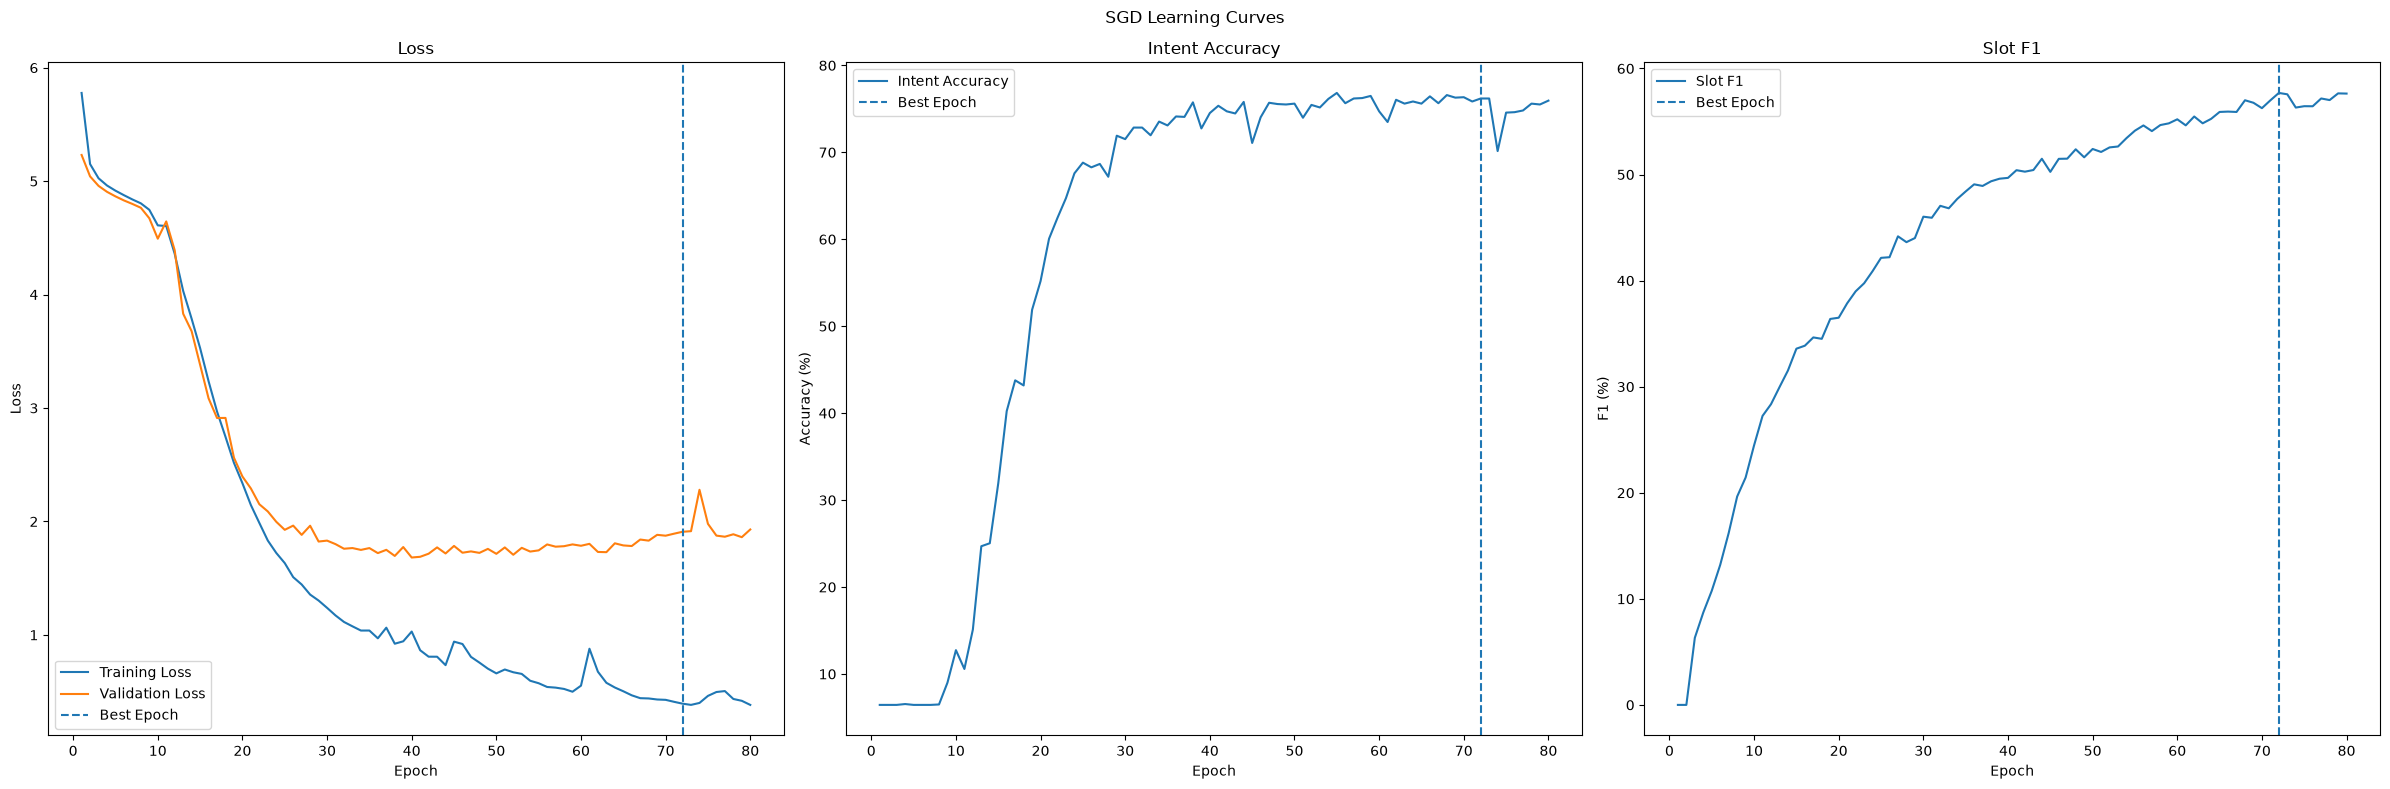

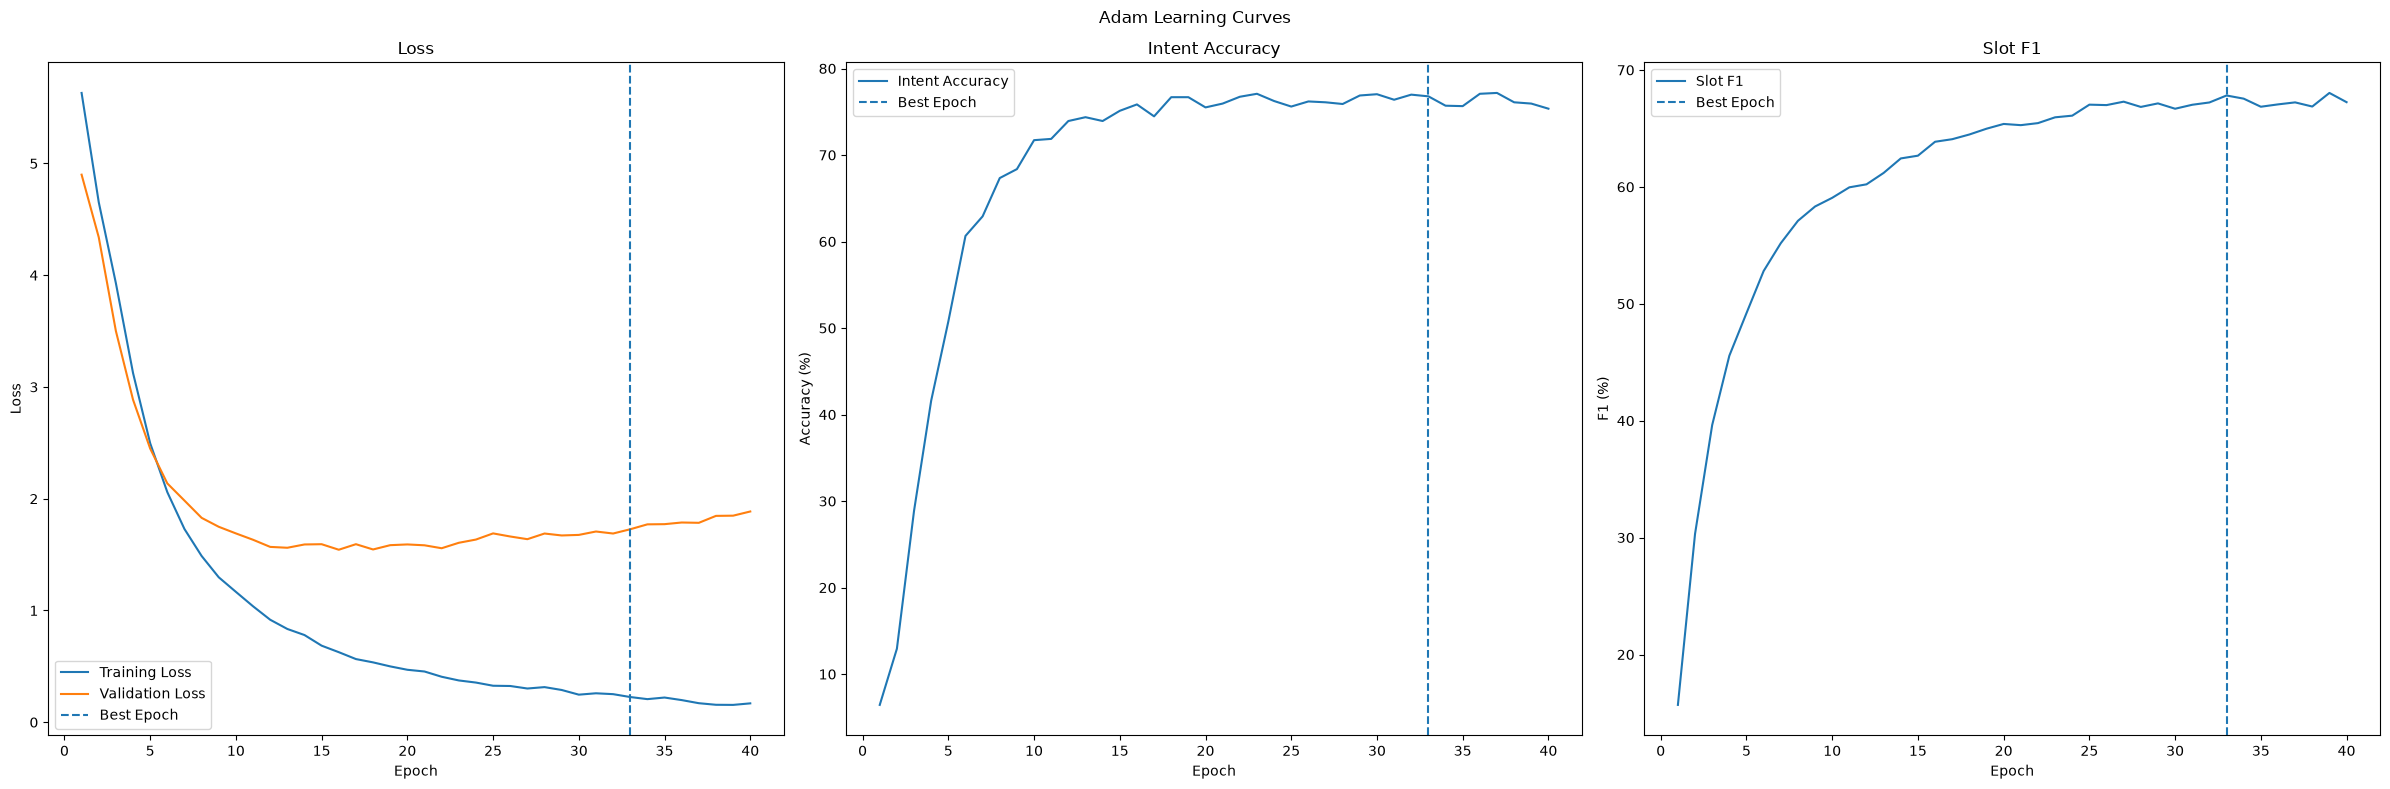

In [236]:
# sgd learning curves
plot_learning_curves(history_sgd, best_epoch_sgd, "SGD Learning Curves")

# adam learning curves
plot_learning_curves(history_adam, best_epoch_adam, "Adam Learning Curves")

# Stage 1: Final Evaluation

In [237]:
# load trained model with adam optimizer, evaluate with validation and test set

adam_checkpoint = "../checkpoints/stage1_adam_base.pt"

# initialise fresh model
eval_model = CustomMassiveModel(
    EMBEDDING_DIM,
    HIDDEN_DIM,
    len(word_to_idx),
    len(tag_to_idx),
    len(intent_to_idx)
)

# load checkpoint of best epoch
checkpoint = torch.load(adam_checkpoint, map_location="cpu", weights_only=True)
eval_model.load_state_dict(checkpoint["model_state_dict"])

print(f"Loaded checkpoint from Epoch {checkpoint['epoch']} with Adam optimizer")

# evaluate on validation set
val_loss, val_accuracy, val_f1 = evaluate(eval_model, val_dl, val_df)

# evaluate on test set
test_loss, test_accuracy, test_f1 = evaluate(eval_model, test_dl, test_df)

print(f"\nValidation Intent Accuracy: {val_accuracy:.2f}%")
print(f"Validation Slot F1: {val_f1:.2f}%")

assert abs(val_accuracy - checkpoint["val_accuracy"]) == 0
assert abs(val_f1 - checkpoint["val_f1"]) == 0

print(f"\nTest Intent Accuracy: {test_accuracy:.2f}%")
print(f"Test Slot F1: {test_f1:.2f}%")

Loaded checkpoint from Epoch 33 with Adam optimizer

Validation Intent Accuracy: 76.78%
Validation Slot F1: 67.82%

Test Intent Accuracy: 75.39%
Test Slot F1: 62.85%


# Stage 2: Experiment 1 (Packed LSTM)

**Weakness** 
- the intent head reads the LSTM state including all padding which may cause results to drift, so intent head may get blurred summary of sentence.
- intent accuracy plateaued at about 76–77% with both SGD and Adam.

**Experiment** 
- sequences are packed so the LSTM stops at each sentence's last real word.
- this prevents drift caused by stepping through padding, which carries no information.

**Results & Analysis:** 
- intent accuracy should show notable increase as it utilises last lstm state, which becomes more accurate due to the exclusion of padding.
- slot f1 should not change significantly as padding is ignored when using hidden state of individual words.

In [240]:
# experiment 1: lstm with packed sequences

class PackedLSTMModel(nn.Module):
    def __init__(self, embedding_dim, hidden_dim, vocab_size, num_tags, num_intent):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.word_embeddings = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first = True)
        self.hidden2tag = nn.Linear(hidden_dim, num_tags)
        self.hidden2intent = nn.Linear(hidden_dim, num_intent)

    def forward(self, sentence):
        lengths = (sentence != 0).sum(dim=1).cpu()   # only consider real tokens
        embeds = self.word_embeddings(sentence)
        packed = pack_padded_sequence(embeds, lengths, batch_first=True, enforce_sorted=False)
        packed_out, (h, c) = self.lstm(packed)
        lstm_out, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=sentence.size(1))  # keep shape aligned with tags
        tag_space = self.hidden2tag(lstm_out)
        intent_space = self.hidden2intent(h[-1])    # for state we only read the last real word
        
        return tag_space, intent_space


packed_lstm_model = PackedLSTMModel(EMBEDDING_DIM, HIDDEN_DIM, len(word_to_idx), len(tag_to_idx), len(intent_to_idx))
words, tags, intents = next(iter(train_dl))
exp1_tag_scores, exp1_intent_scores = packed_lstm_model(words)
print(exp1_tag_scores.shape, exp1_intent_scores.shape)

torch.Size([64, 19, 107]) torch.Size([64, 60])


In [241]:
# run lstm model

torch.manual_seed(SEED)

# build packed sequence model
packed_lstm_model = PackedLSTMModel(EMBEDDING_DIM, HIDDEN_DIM, len(word_to_idx), len(tag_to_idx), len(intent_to_idx))

# define optimizer
optimizer = optim.Adam(packed_lstm_model.parameters(), lr=LEARNING_RATE_ADAM)

# train model, get results
history_exp1, best_epoch_exp1, best_score_exp1 = train_model(packed_lstm_model, optimizer, NUM_EPOCHS_ADAM, "../checkpoints/stage2_exp1_packed.pt")

Epoch 1/40 | Train Loss: 5.3368 | Val Loss: 3.9114 | Intent Accuracy: 35.51% | Slot F1: 3.52% | Time: 5.09s
Epoch 2/40 | Train Loss: 3.2131 | Val Loss: 2.7183 | Intent Accuracy: 55.09% | Slot F1: 22.42% | Time: 4.10s
Epoch 3/40 | Train Loss: 2.3003 | Val Loss: 2.1191 | Intent Accuracy: 67.04% | Slot F1: 32.05% | Time: 4.65s
Epoch 4/40 | Train Loss: 1.7714 | Val Loss: 1.8127 | Intent Accuracy: 72.50% | Slot F1: 42.66% | Time: 3.85s
Epoch 5/40 | Train Loss: 1.4360 | Val Loss: 1.6077 | Intent Accuracy: 75.90% | Slot F1: 48.39% | Time: 3.88s
Epoch 6/40 | Train Loss: 1.1951 | Val Loss: 1.4955 | Intent Accuracy: 77.27% | Slot F1: 52.26% | Time: 3.83s
Epoch 7/40 | Train Loss: 1.0141 | Val Loss: 1.4133 | Intent Accuracy: 77.91% | Slot F1: 55.46% | Time: 4.00s
Epoch 8/40 | Train Loss: 0.8729 | Val Loss: 1.3521 | Intent Accuracy: 79.34% | Slot F1: 57.11% | Time: 4.55s
Epoch 9/40 | Train Loss: 0.7499 | Val Loss: 1.3228 | Intent Accuracy: 79.64% | Slot F1: 58.96% | Time: 4.22s
Epoch 10/40 | Train 

# Stage 2: Experiment 2 (Packed Bi-Directional LSTM)

**Weakness**
- with uni-directional lstm, word tags are only aware of words before it. slot boundaries spanning multiple words may be harder to identify accurately because only preceding context is available at each token

**Experiment**
- instead of only performing a forward pass in uni-directional lstms, bi-directional lstms include a backward pass to allow a word to capture both context before and after it.

**Results & Analysis**
- slot f1 increases substantially as each word now has context from the words that appear after it.
- intent stayed relatively flat with minimal gains. first possible cause simply is that a unidirectional lstm already sufficiently captures information from the entire sentence through its final hidden state, improved further through packing brought over from exp 1. second possible cause is that the text for the dataset is relatively short, hence it does not benefit significantly from additional context of the additional pass.
- overfitting sets in earlier. training loss falls close to 0 at 0.007, while validation loss reaches its minimum at epoch 11 (vs epoch 16 for the baseline) before increasing. one possible cause is that bidirectionality introduces more parameters, allowing the model to memorise training samples faster without necessarily improving generalisation. with a relatively limited dataset size, this further exacerbates the problem of overfitting. however, validation loss remains lower than the baseline throughout, so the model still generalises better overall.

In [242]:
# experiment 2: bi-directional lstm with packed sequences

class PackedBiLSTMModel(nn.Module):
    def __init__(self, embedding_dim, hidden_dim, vocab_size, num_tags, num_intent):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.word_embeddings = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True) # set bidirectional boolean flag to enable backward pass
        self.hidden2tag = nn.Linear(2 * hidden_dim, num_tags)
        self.hidden2intent = nn.Linear(2 * hidden_dim, num_intent)

    def forward(self, sentence):
        lengths = (sentence != 0).sum(dim=1).cpu()
        embeds = self.word_embeddings(sentence)
        packed = pack_padded_sequence(embeds, lengths, batch_first=True, enforce_sorted=False)
        packed_out, (h, c) = self.lstm(packed)
        lstm_out, _ = pad_packed_sequence(packed_out, batch_first=True,
                                          total_length=sentence.size(1))
        tag_space = self.hidden2tag(lstm_out)

        intent_space = self.hidden2intent(torch.cat([h[0], h[1]], dim=1))

        return tag_space, intent_space

packed_bilstm_model = PackedBiLSTMModel(EMBEDDING_DIM, HIDDEN_DIM, len(word_to_idx), len(tag_to_idx), len(intent_to_idx))
words, tags, intents = next(iter(train_dl))
exp2_tag_scores, exp2_intent_scores = packed_bilstm_model(words)
print(exp2_tag_scores.shape, exp2_intent_scores.shape)

torch.Size([64, 19, 107]) torch.Size([64, 60])


In [256]:
# check for total parameter cap

total_params = sum(p.numel() for p in packed_bilstm_model.parameters())
trainable_params = sum(p.numel() for p in packed_bilstm_model.parameters() if p.requires_grad)

print(f"Total parameters (includes embedding layer/word vectors): {total_params:,}")
print(f"Total trainable parameters: {trainable_params:,}")

if total_params < 20_000_000:
    print(f"Parameter count is within range, {total_params:,} < 20,000,000.")
else:
    assert False, f"Parameter count exceeded range, {total_params:,} > 20,000,000."

Total parameters (includes embedding layer/word vectors): 808,839
Total trainable parameters: 808,839
Parameter count is within range, 808,839 < 20,000,000.


In [243]:
# inspect tensor shapes

with torch.no_grad():
    lengths = (words != 0).sum(dim=1).cpu()
    embeds = packed_bilstm_model.word_embeddings(words)
    packed = pack_padded_sequence(embeds, lengths, batch_first=True, enforce_sorted=False)
    packed_out, (h, c) = packed_bilstm_model.lstm(packed)
    lstm_out, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=words.size(1))
    intent_input = torch.cat([h[0], h[1]], dim=1)

print(f"words:        {words.shape}")         # [batch, seq_len]
print(f"embeds:       {embeds.shape}")        # [batch, seq_len, EMBEDDING_DIM]
print(f"lstm_out:     {lstm_out.shape}")      # [batch, seq_len, 2*HIDDEN_DIM]  forward + backward joined
print(f"h:            {h.shape}")             # [2, batch, HIDDEN_DIM]        one final state per direction
print(f"intent input: {intent_input.shape}")  # [batch, 2*HIDDEN_DIM]           h[0] and h[1] joined
print(f"tag scores:   {exp2_tag_scores.shape}")     # [batch, seq_len, tag_size]
print(f"intent scores:{exp2_intent_scores.shape}")  # [batch, intent_size]

words:        torch.Size([64, 19])
embeds:       torch.Size([64, 19, 100])
lstm_out:     torch.Size([64, 19, 256])
h:            torch.Size([2, 64, 128])
intent input: torch.Size([64, 256])
tag scores:   torch.Size([64, 19, 107])
intent scores:torch.Size([64, 60])


In [248]:
# run lstm model

torch.manual_seed(SEED)

# build packed sequence model
packed_bilstm_model = PackedBiLSTMModel(EMBEDDING_DIM, HIDDEN_DIM, len(word_to_idx), len(tag_to_idx), len(intent_to_idx))

# define optimizer
optimizer = optim.Adam(packed_bilstm_model.parameters(), lr=LEARNING_RATE_ADAM)

# train model, get results
history_exp2, best_epoch_exp2, best_score_exp2 = train_model(packed_bilstm_model, optimizer, NUM_EPOCHS_ADAM, "../checkpoints/stage2_exp2_bilstm.pt")

Epoch 1/40 | Train Loss: 4.6402 | Val Loss: 2.9969 | Intent Accuracy: 53.12% | Slot F1: 19.12% | Time: 5.72s
Epoch 2/40 | Train Loss: 2.3233 | Val Loss: 1.9688 | Intent Accuracy: 70.09% | Slot F1: 40.34% | Time: 5.85s
Epoch 3/40 | Train Loss: 1.5587 | Val Loss: 1.6008 | Intent Accuracy: 75.36% | Slot F1: 49.55% | Time: 5.63s
Epoch 4/40 | Train Loss: 1.1638 | Val Loss: 1.4230 | Intent Accuracy: 78.41% | Slot F1: 53.63% | Time: 5.78s
Epoch 5/40 | Train Loss: 0.9089 | Val Loss: 1.3331 | Intent Accuracy: 78.65% | Slot F1: 56.27% | Time: 6.13s
Epoch 6/40 | Train Loss: 0.7181 | Val Loss: 1.2810 | Intent Accuracy: 79.59% | Slot F1: 59.17% | Time: 5.71s
Epoch 7/40 | Train Loss: 0.5792 | Val Loss: 1.2511 | Intent Accuracy: 80.47% | Slot F1: 60.56% | Time: 6.09s
Epoch 8/40 | Train Loss: 0.4669 | Val Loss: 1.2326 | Intent Accuracy: 80.67% | Slot F1: 61.99% | Time: 5.74s
Epoch 9/40 | Train Loss: 0.3793 | Val Loss: 1.2254 | Intent Accuracy: 80.91% | Slot F1: 63.65% | Time: 5.60s
Epoch 10/40 | Train

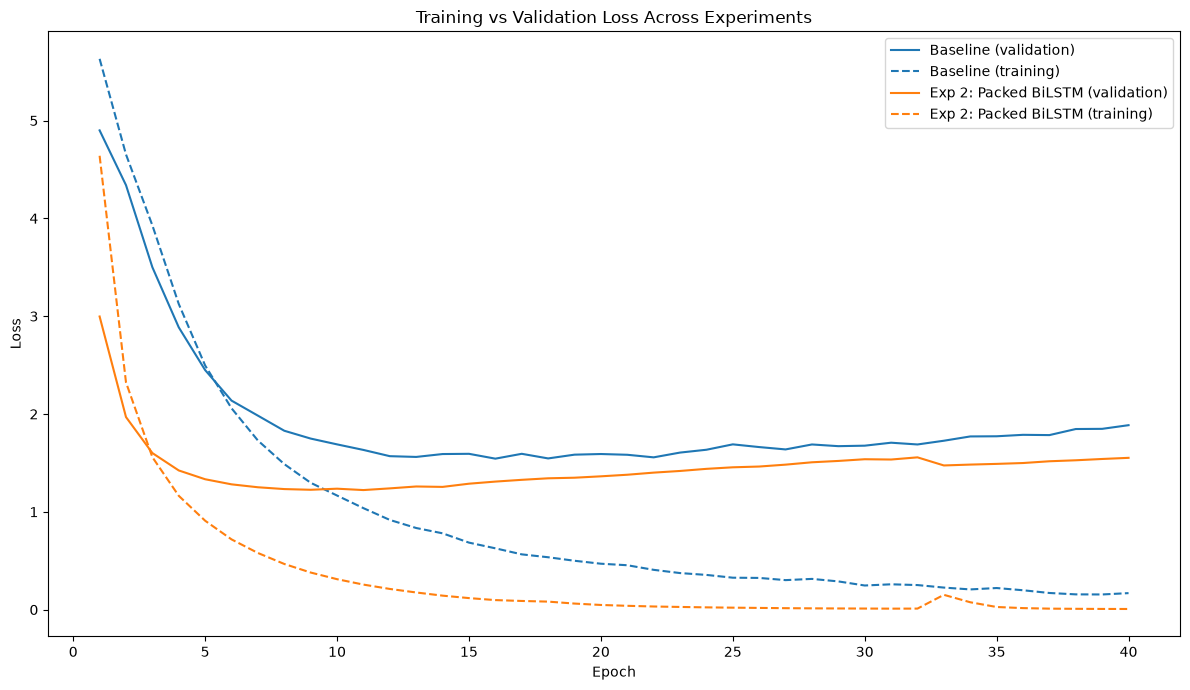

In [254]:
plot_loss_comparison({
    "Baseline": history_adam,
    "Exp 2: Packed BiLSTM": history_exp2,
}, "Training vs Validation Loss Across Experiments")

# Stage 2: Experiment 3 (Packed Bi-Directional LSTM with Dropout)

**Weakness** 
- experiment 2 showed earlier signs of overfitting. training loss neared 0 with validation loss lowest at epoch 11. as such, we include dropout to tackle overfitting.

**Experiment**
- dropout randomly zeroes some values in the word embeddings, the bilstm outputs and the intent input during training. this forces the model to reduce reliance on specific features and learn more distributed and robust ones. a smaller dataset such as massive is more prone to overfitting. as such, we experimented with larger dropout rates to increase the effect.
- we experiment with a set of 0.3-0.5.

**Results & Analysis:**
- with epoch limits of 40 and 80, the best epoch was the final one, suggesting the model is still learning. as such, we raise the epoch limit to 100 for exp 3.
- best epoch is raised from 28 to 90+. main reason is that dropout makes training noisier. the model memorises more slowly and learns useful patterns over a longer time.
- dropout rate of 0.3 performed best, though the gap is small. heavier dropout improved intent accuracy but reduced slot f1. slot tagging relies on exact words, so heavy dropout on the embeddings removes the information it needs most, while intent depends on the overall sentence and benefits from stronger regularisation.
- overfitting is significantly less. dropout makes learning harder by randomly zeroing values, preventing training loss from collapsing to 0. since it learns more meaningful patterns, it generalises better. this causes validation loss to stay lower and reach its minimum later. however, overfitting is reduced rather than removed: at 0.3, validation loss still rises after epoch ~20, while heavier rates kept it lower for longer.
- significant gains across both slot f1 and intent accuracy. slot values are often rare words, causing the model to memorise them without dropout. dropout forces the model to use surrounding context, rather than memorising the specific words. intent improves due to less reliance on specific features or memorised phrases.

In [271]:
# experiment 3: packed bi-directional lstm with dropout at 0.3

class PackedBiLSTMDOModel(nn.Module):
    def __init__(self, embedding_dim, hidden_dim, vocab_size, num_tags, num_intent, dropout_rate=0.3):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.word_embeddings = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout_rate)
        self.hidden2tag = nn.Linear(2 * hidden_dim, num_tags)
        self.hidden2intent = nn.Linear(2 * hidden_dim, num_intent)

    def forward(self, sentence):
        lengths = (sentence != 0).sum(dim=1).cpu()

        embeds = self.dropout(self.word_embeddings(sentence))
        packed = pack_padded_sequence(embeds, lengths, batch_first=True, enforce_sorted=False)

        packed_out, (h, c) = self.lstm(packed)
        lstm_out, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=sentence.size(1)
        )

        # dropout before slot classification
        lstm_out = self.dropout(lstm_out)
        tag_space = self.hidden2tag(lstm_out)

        # dropout before intent classification
        intent_input = torch.cat([h[0], h[1]], dim=1)
        intent_space = self.hidden2intent(self.dropout(intent_input))

        return tag_space, intent_space

In [272]:
DROPOUT_RATES = [0.3, 0.4, 0.5]
exp3_results = {}

for dropout in DROPOUT_RATES:
    print(f"\nRun Packed Bi-LSTM Model with Dropout at Dropout Rate: {dropout}\n")

    torch.manual_seed(SEED)

    model = PackedBiLSTMDOModel(
        EMBEDDING_DIM, HIDDEN_DIM,
        len(word_to_idx), len(tag_to_idx), len(intent_to_idx),
        dropout_rate=dropout
    )

    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE_ADAM)

    checkpoint_path = f"../checkpoints/stage2_exp3/{dropout}/stage2_exp3_dropout_{dropout}.pt"

    history, best_epoch, best_score = train_model(model, optimizer, NUM_EPOCHS_EXP3, checkpoint_path)

    exp3_results[dropout] = {
        "history": history,
        "best_epoch": best_epoch,
        "best_score": best_score,
        "checkpoint_path": checkpoint_path,
    }

best_dropout = max(exp3_results, key=lambda d: exp3_results[d]["best_score"])
print(f"\nBest dropout rate: {best_dropout} | "
      f"Epoch {exp3_results[best_dropout]['best_epoch']} | "
      f"Validation score {exp3_results[best_dropout]['best_score']:.2f}% | "
      f"{exp3_results[best_dropout]['checkpoint_path']}")


Run Packed Bi-LSTM Model with Dropout at Dropout Rate: 0.3

Epoch 1/100 | Train Loss: 5.0485 | Val Loss: 3.4577 | Intent Accuracy: 43.43% | Slot F1: 12.03% | Time: 6.64s
Epoch 2/100 | Train Loss: 3.0632 | Val Loss: 2.3404 | Intent Accuracy: 62.91% | Slot F1: 32.13% | Time: 7.28s
Epoch 3/100 | Train Loss: 2.2940 | Val Loss: 1.8694 | Intent Accuracy: 70.73% | Slot F1: 40.87% | Time: 6.11s
Epoch 4/100 | Train Loss: 1.8848 | Val Loss: 1.6064 | Intent Accuracy: 74.37% | Slot F1: 47.97% | Time: 6.02s
Epoch 5/100 | Train Loss: 1.6138 | Val Loss: 1.4579 | Intent Accuracy: 76.49% | Slot F1: 53.40% | Time: 5.90s
Epoch 6/100 | Train Loss: 1.4436 | Val Loss: 1.3591 | Intent Accuracy: 77.96% | Slot F1: 55.68% | Time: 6.02s
Epoch 7/100 | Train Loss: 1.2928 | Val Loss: 1.2880 | Intent Accuracy: 79.24% | Slot F1: 56.86% | Time: 6.01s
Epoch 8/100 | Train Loss: 1.1771 | Val Loss: 1.2179 | Intent Accuracy: 80.32% | Slot F1: 60.29% | Time: 5.88s
Epoch 9/100 | Train Loss: 1.0785 | Val Loss: 1.1953 | Inten

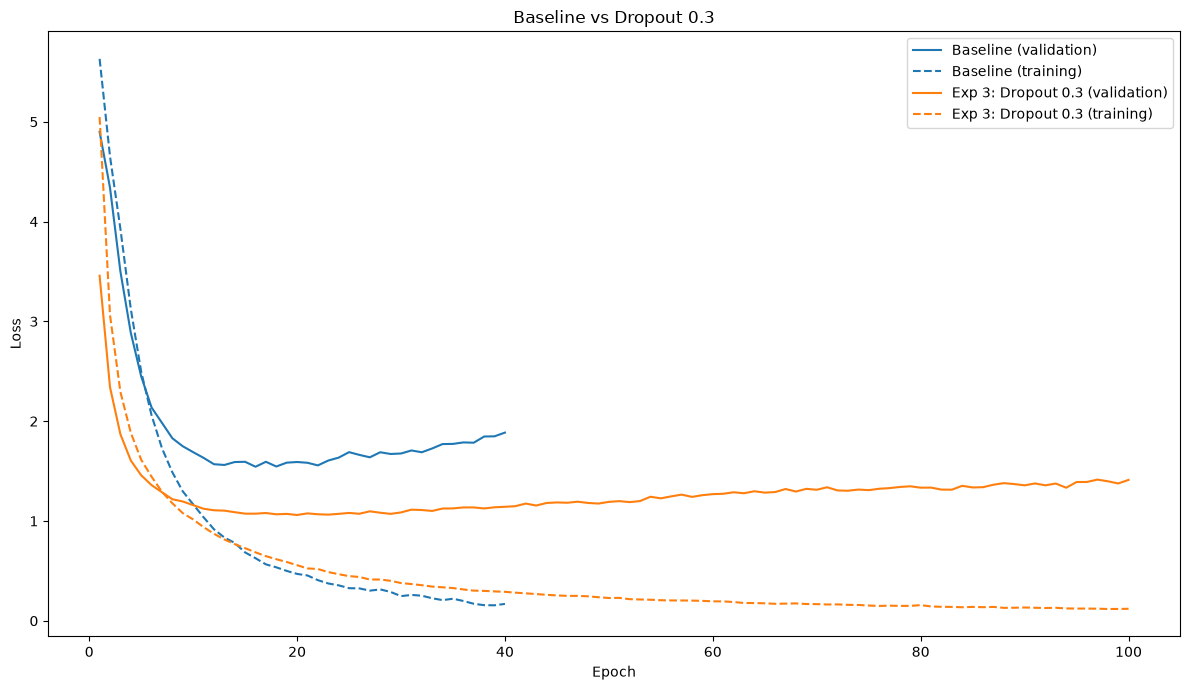

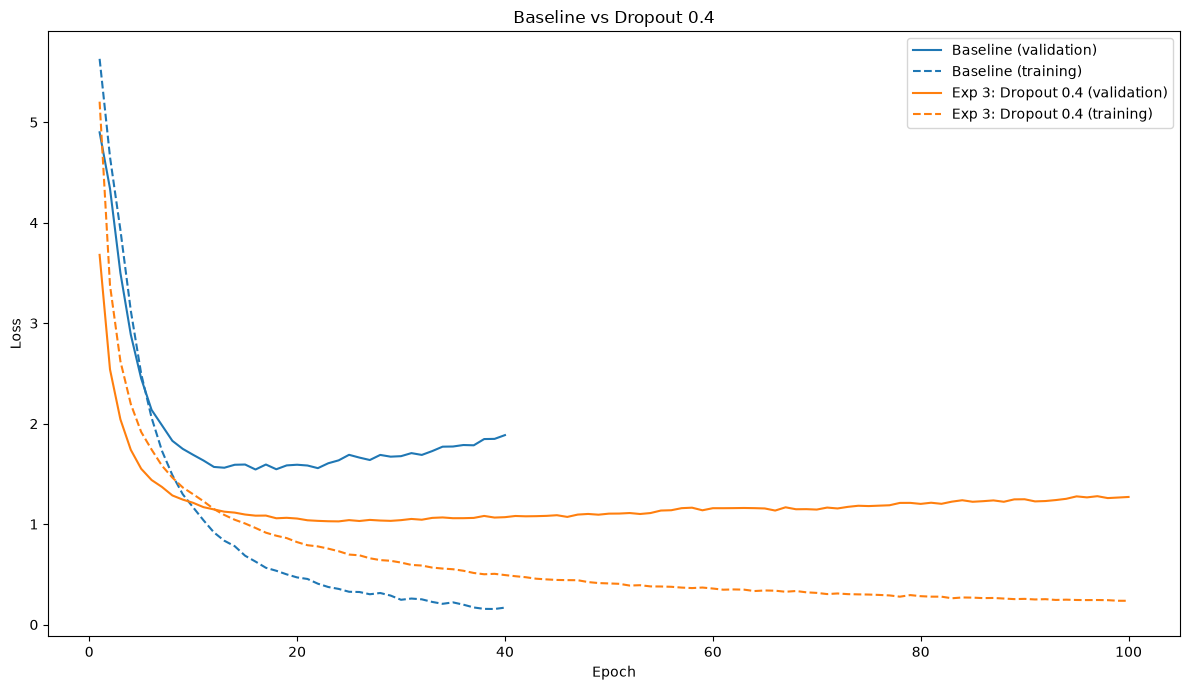

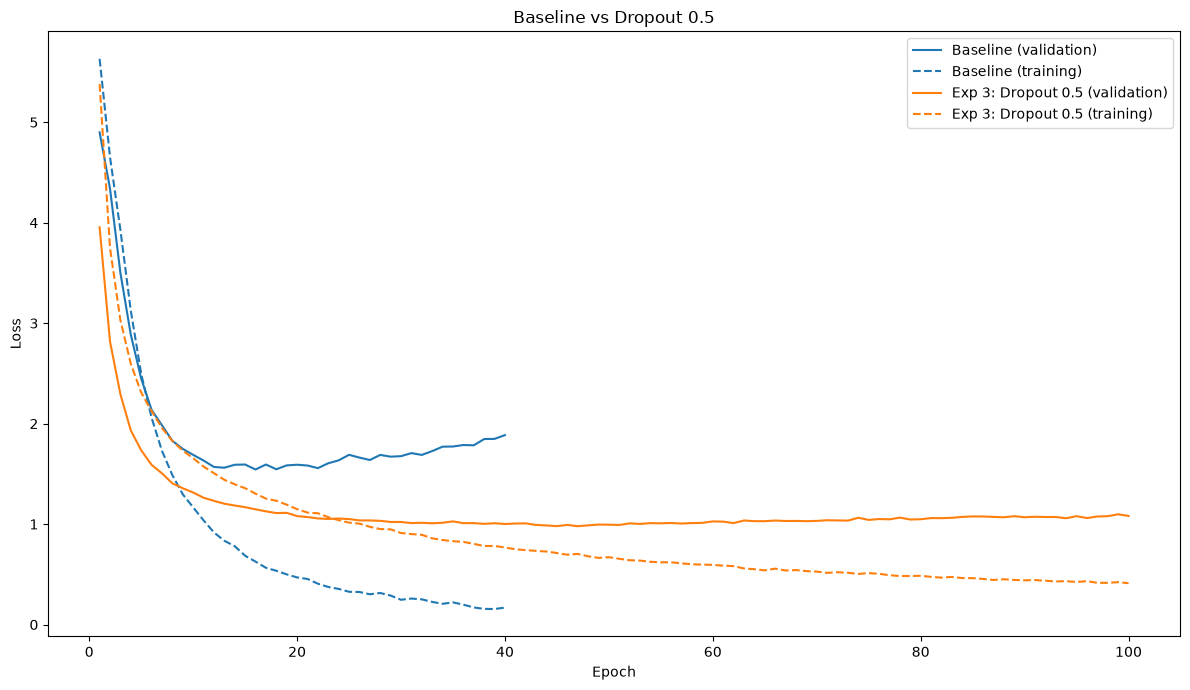

In [273]:
plot_loss_comparison({
    "Baseline": history_adam,
    "Exp 3: Dropout 0.3": exp3_results[0.3]["history"],
}, "Baseline vs Dropout 0.3")

plot_loss_comparison({
    "Baseline": history_adam,
    "Exp 3: Dropout 0.4": exp3_results[0.4]["history"],
}, "Baseline vs Dropout 0.4")

plot_loss_comparison({
    "Baseline": history_adam,
    "Exp 3: Dropout 0.5": exp3_results[0.5]["history"],
}, "Baseline vs Dropout 0.5")

# Stage 2: Experiment 4 (Packed Bi-Directional LSTM with Dropout, Gradient Clipping & Learning Rate Scheduler)

**Weakness**
- best epochs for experiment 3 occurred late around 90+ epochs. validation scores fluctuated noticeably between epochs near the end. with constant learning rate, the model makes relatively large updates making it harder to settle. as such, we consider lr scheduler.
- gradient clipping is also included as a measure to safeguard against spikes causing unstable updates.

**Experiment**
- a cosine lr scheduler lowers the learning rate along a fixed curve over the 100 epochs, from 0.001 to 1e-5. earlier epochs keep a larger lr for faster progress, and the lr drops most towards the end, where we expect smaller updates to stabilise the scores and settle at a better result. cosine was chosen because it stays high while the model is still improving and needs no extra settings tuned on validation.
- gradient clipping caps the size of single updates, preventing occasional drastic updates from destabilising training. gradient clipping was not tuned as it was only added as a safeguard, given no spikes observed after dropout in exp 3.

**Results & Analysis:**
- combined validation score dropped from 81.22% to 79.87% at epoch 88. intent stayed similar, while slot f1 fell.
- the scheduler fixed late fluctuation. however, it settled at a lower score. lr was already halved by around epoch 50, but in exp 3 slot f1 was still improving after epoch 50, at the full lr. lowering lr too early limited the model's ability to learn, especially for slots.
- part of the lead in exp 3 may come from a spurious spike in a fluctuating curve, which might be optimistic. however, exp 3 is still ahead when averaged over its last 10 epochs (~80.7% vs ~79.8%), as such, it still wins.
- clipping and the scheduler were added together, so their individual effects cannot be separated. since no loss spikes appeared after dropout, clipping likely had little effect and is not needed.
- a slower or later decay might avoid cutting learning short while keeping the stabilisation, giving more reliable endpoints, but expected gains are small, so the experiment is not kept. the final model continues with exp 3’s setup.

In [281]:
print("\nRun Packed Bi-LSTM Model with Dropout, Gradient Clipping and Cosine LR Scheduler\n")

torch.manual_seed(SEED)

model = PackedBiLSTMDOModel(
    EMBEDDING_DIM, HIDDEN_DIM,
    len(word_to_idx), len(tag_to_idx), len(intent_to_idx),
    dropout_rate=DROPOUT
)

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE_ADAM)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=NUM_EPOCHS_EXP3,
    eta_min=1e-5
)

checkpoint_path = "../checkpoints/stage2_exp4_gclr.pt"

history_exp4, best_epoch_exp4, best_score_exp4 = train_model(
    model,
    optimizer,
    NUM_EPOCHS_EXP3,
    checkpoint_path,
    max_grad_norm=MAX_GRAD_NORM,
    scheduler=scheduler
)

exp4_results = {
    "history": history_exp4,
    "best_epoch": best_epoch_exp4,
    "best_score": best_score_exp4,
    "checkpoint_path": checkpoint_path,
}


Run Packed Bi-LSTM Model with Dropout, Gradient Clipping and Cosine LR Scheduler

Epoch 1/100 | Train Loss: 5.0380 | Val Loss: 3.4241 | Intent Accuracy: 43.93% | Slot F1: 12.51% | LR: 0.001000 | Time: 6.92s
Epoch 2/100 | Train Loss: 3.0747 | Val Loss: 2.3831 | Intent Accuracy: 62.37% | Slot F1: 30.51% | LR: 0.001000 | Time: 6.24s
Epoch 3/100 | Train Loss: 2.3352 | Val Loss: 1.9046 | Intent Accuracy: 70.24% | Slot F1: 40.21% | LR: 0.000999 | Time: 6.40s
Epoch 4/100 | Train Loss: 1.9177 | Val Loss: 1.6317 | Intent Accuracy: 73.64% | Slot F1: 47.35% | LR: 0.000998 | Time: 6.54s
Epoch 5/100 | Train Loss: 1.6392 | Val Loss: 1.4739 | Intent Accuracy: 75.90% | Slot F1: 53.04% | LR: 0.000996 | Time: 7.33s
Epoch 6/100 | Train Loss: 1.4583 | Val Loss: 1.3660 | Intent Accuracy: 77.47% | Slot F1: 55.66% | LR: 0.000994 | Time: 6.35s
Epoch 7/100 | Train Loss: 1.3019 | Val Loss: 1.2891 | Intent Accuracy: 79.29% | Slot F1: 57.48% | LR: 0.000991 | Time: 6.23s
Epoch 8/100 | Train Loss: 1.1809 | Val Los